In [ ]:
# Pt 5. Machine Learning Algorithm Comparison
# Comparing several machine learning algorithm to build a regression model
%pip install lazypredict scikit-learn pandas seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
import lazypredict
from lazypredict.Supervised import LazyRegressor

In [3]:
# Load data set
df = pd.read_csv('bioactivity_XY_dataset.csv')
df.head()  # Display the first few rows of the DataFrame

,PubchemFP0,PubchemFP1,PubchemFP2,PubchemFP3,PubchemFP4,PubchemFP5,PubchemFP6,PubchemFP7,PubchemFP8,PubchemFP9,...,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880,pIC50
0,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,7.387216
1,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,6.769551
2,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,5.031517
3,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,3.301030
4,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,2.522879


In [4]:
# Separate X as PubChem and Y as pIC50
X = df.drop('pIC50', axis=1)
Y = df.pIC50

In [5]:
# Data pre-processing
X.shape

(791, 881)

In [6]:
## Remove low variance features
from sklearn.feature_selection import VarianceThreshold
selection = VarianceThreshold(threshold=(.8 * (1 - .8)))    
X = selection.fit_transform(X)
X.shape

(791, 145)

In [7]:
# Perform data splitting using 80/20 ratio
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [8]:
# Compare ML algorithms
# Defines and builds the lazyclassifier
# It has 39 ML model / algorithm

clf = LazyRegressor(verbose = 0,ignore_warnings = True, custom_metric = None)
models_train,predictions_train = clf.fit(X_train, X_train, Y_train, Y_train)
models_test,predictions_test = clf.fit(X_train, X_test, Y_train, Y_test)

In [9]:
# Performance table of the training set (80% subset)
models_train

,Adjusted R-Squared,R-Squared,RMSE,Time Taken
Model,,,,
DecisionTreeRegressor,9.564474e-01,9.664555e-01,3.013197e-01,0.063923
ExtraTreeRegressor,9.564474e-01,9.664555e-01,3.013197e-01,0.068747
ExtraTreesRegressor,9.564474e-01,9.664555e-01,3.013197e-01,1.700518
GaussianProcessRegressor,9.551386e-01,9.654475e-01,3.058136e-01,0.389512
RandomForestRegressor,9.213536e-01,9.394260e-01,4.049115e-01,1.365419
BaggingRegressor,9.057066e-01,9.273747e-01,4.433647e-01,0.197722
MLPRegressor,8.896662e-01,9.150203e-01,4.795952e-01,1.244731
HistGradientBoostingRegressor,8.755615e-01,9.041567e-01,5.093285e-01,0.628633
GradientBoostingRegressor,8.053691e-01,8.500941e-01,6.369810e-01,0.588769


In [10]:
# Performance table of the test set (20% subset)
models_test

,Adjusted R-Squared,R-Squared,RMSE,Time Taken
Model,,,,
MLPRegressor,-1.914021e+00,7.602388e-01,8.275320e-01,1.259960
RandomForestRegressor,-2.006853e+00,7.526007e-01,8.406101e-01,1.278390
HistGradientBoostingRegressor,-2.021332e+00,7.514094e-01,8.426315e-01,0.724174
GradientBoostingRegressor,-2.186119e+00,7.378510e-01,8.653054e-01,0.552892
SVR,-2.240628e+00,7.333660e-01,8.726761e-01,0.136389
BaggingRegressor,-2.290037e+00,7.293007e-01,8.793037e-01,0.185254
NuSVR,-2.347636e+00,7.245616e-01,8.869672e-01,0.104209
KNeighborsRegressor,-2.429672e+00,7.178118e-01,8.977693e-01,0.038404
PoissonRegressor,-2.692095e+00,6.962200e-01,9.314829e-01,0.066716


C:\Users\Andina Angelia\AppData\Local\Temp\ipykernel_4912\2540188923.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(y = models_train.index, x = "R-Squared", data = models_train, palette = "viridis")


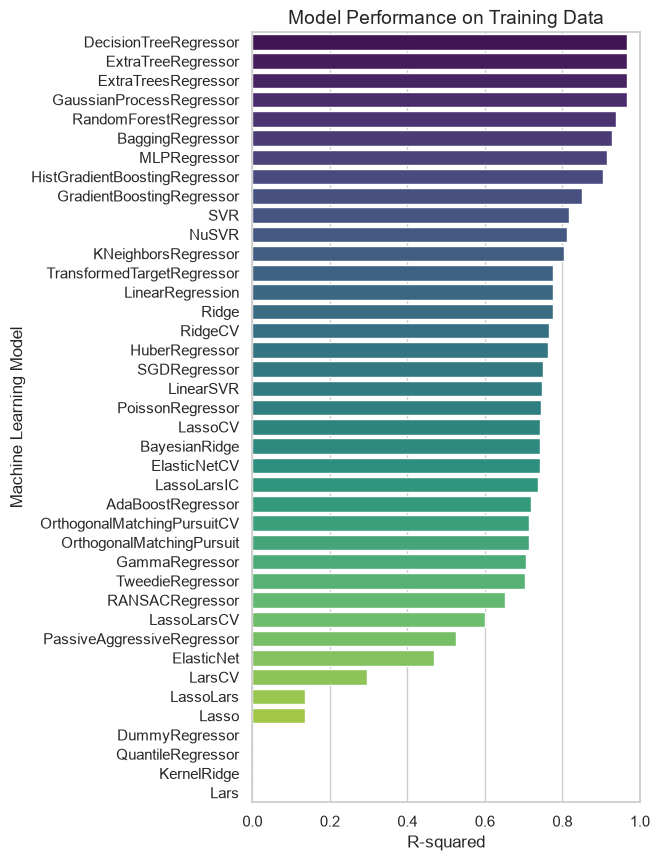

In [11]:
# Data Visualization of Model Performance
# Bar plot of R-squared values
import matplotlib.pyplot as plt

#train["R-Squared"] = [0 if i < 0 else i for i in train.iloc[:,0] ]

plt.figure(figsize = (5, 10))
sns.set_theme(style = "whitegrid")

ax = sns.barplot(y = models_train.index, x = "R-Squared", data = models_train, palette = "viridis")
ax.set(xlim = (0, 1))

ax.set_xlabel("R-squared", fontsize = 12)
ax.set_ylabel("Machine Learning Model", fontsize = 12)
ax.set_title("Model Performance on Training Data", fontsize = 14)

plt.savefig(
    r"D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery\R2_models.png",
    dpi=300,
    bbox_inches="tight"
)

C:\Users\Andina Angelia\AppData\Local\Temp\ipykernel_4912\1418808654.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(y = models_train.index, x = "RMSE", data = models_train, palette = "viridis")


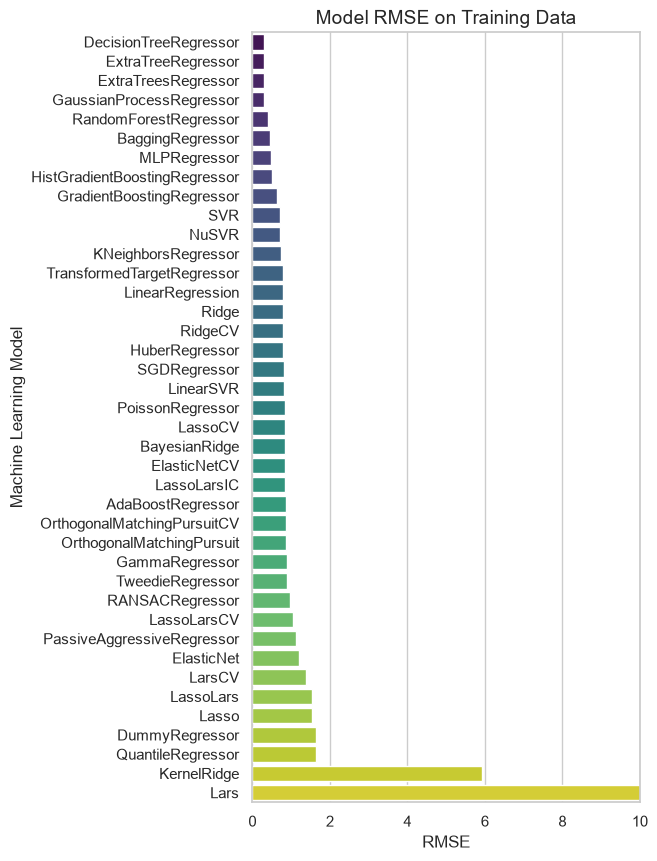

In [12]:
plt.figure(figsize = (5, 10))
sns.set_theme(style = "whitegrid")

ax = sns.barplot(y = models_train.index, x = "RMSE", data = models_train, palette = "viridis")
ax.set(xlim=(0, 10))

ax.set_xlabel("RMSE", fontsize = 12)
ax.set_ylabel("Machine Learning Model", fontsize = 12)
ax.set_title("Model RMSE on Training Data", fontsize = 14)

plt.savefig(
    r"D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery\RMSE_models.png",
    dpi=300,
    bbox_inches="tight"
)

C:\Users\Andina Angelia\AppData\Local\Temp\ipykernel_4912\2121031052.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(y = models_train.index, x = "Time Taken", data = models_train, palette = "viridis")


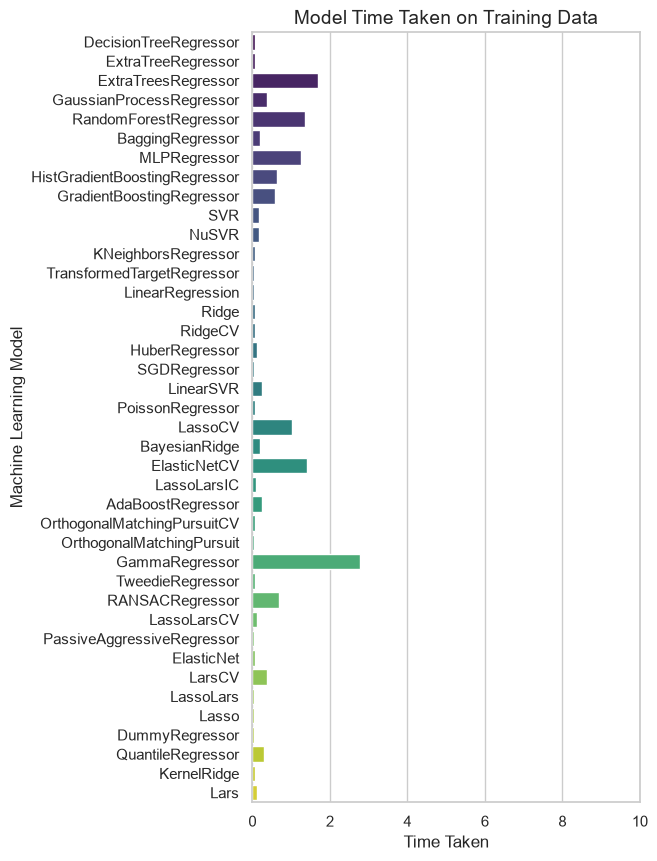

In [13]:
plt.figure(figsize = (5, 10))
sns.set_theme(style = "whitegrid")

ax = sns.barplot(y = models_train.index, x = "Time Taken", data = models_train, palette = "viridis")
ax.set(xlim=(0, 10))

ax.set_xlabel("Time Taken", fontsize = 12)
ax.set_ylabel("Machine Learning Model", fontsize = 12)
ax.set_title("Model Time Taken on Training Data", fontsize = 14)

plt.savefig(
    r"D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery\Time_Taken_models.png",
    dpi=300,
    bbox_inches="tight"
)